In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("lifecyclesavings.csv")

df

,Contry,sr,pop15,pop75,dpi,ddpi
0,Australia,11.43,29.35,2.87,2329.68,2.87
1,Austria,12.07,23.32,4.41,1507.99,3.93
2,Belgium,13.17,23.80,4.43,2108.47,3.82
3,Bolivia,5.75,41.89,1.67,189.13,0.22
4,Brazil,12.88,42.19,0.83,728.47,4.56
5,Canada,8.79,31.72,2.85,2982.88,2.43
6,Chile,0.60,39.74,1.34,662.86,2.67
7,China,11.90,44.75,0.67,289.52,6.51
8,Colombia,4.98,46.64,1.06,276.65,3.08
9,Costa Rica,10.78,47.64,1.14,471.24,2.80


In [3]:
df.shape

(50, 6)

In [4]:
df.isna().sum()

Contry    0
sr        0
pop15     0
pop75     0
dpi       0
ddpi      0
dtype: int64

In [5]:
df.mean(numeric_only=True)

sr          9.6710
pop15      35.0896
pop75       2.2930
dpi      1106.7584
ddpi        3.7576
dtype: float64

My prompt log:
You are helping with clustering the countries into groups by their savings behavior
and visualizing the result.
My CSV has columns: [Contry 	sr 	pop15 	pop75 	dpi 	ddpi + str float float float float float].
Write Python using pandas and seaborn to:
(1) summarize missing data,
(2) produce a working clustering,
(3) produce one labeled chart.
Explain each step in comments.

First five rows:
     Country     sr  pop15  pop75      dpi  ddpi
0  Australia  11.43  29.35   2.87  2329.68  2.87
1    Austria  12.07  23.32   4.41  1507.99  3.93
2    Belgium  13.17  23.80   4.43  2108.47  3.82
3    Bolivia   5.75  41.89   1.67   189.13  0.22
4     Brazil  12.88  42.19   0.83   728.47  4.56

Missing values per column:
Country    0
sr         0
pop15      0
pop75      0
dpi        0
ddpi       0
dtype: int64

Missing data percentage:
Country    0.0
sr         0.0
pop15      0.0
pop75      0.0
dpi        0.0
ddpi       0.0
dtype: float64

Country cluster assignments:
       Country  Cluster
       Bolivia        0
         Chile        0
      Colombia        0
    Costa Rica        0
       Ecuador        0
     Guatamala        0
      Honduras        0
         India        0
         Korea        0
      Malaysia        0
     Nicaragua        0
        Panama        0
      Paraguay        0
          Peru        0
   Philippines        0
       Tunisia        0
 

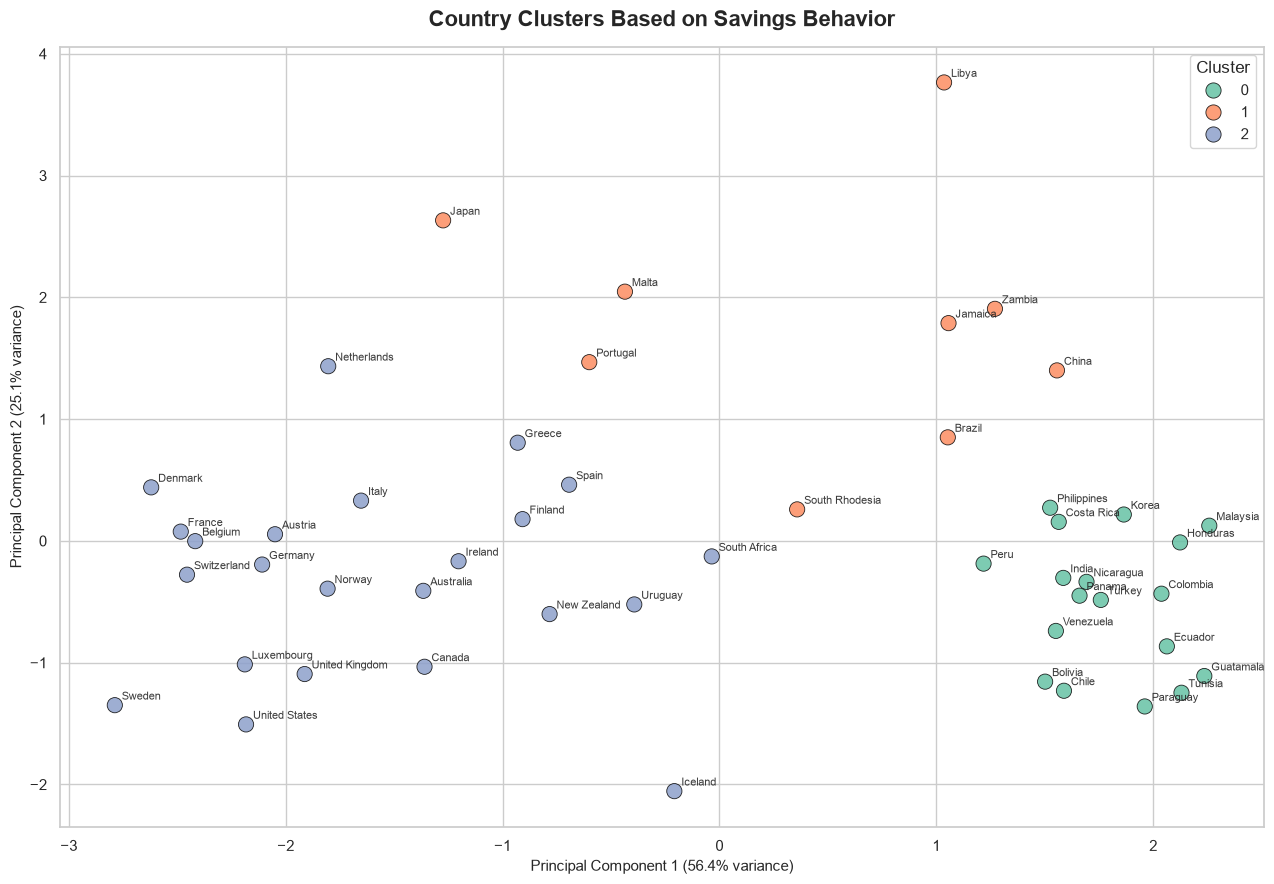

In [6]:

# Import the libraries needed for data analysis, visualization, and clustering
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# --------------------------------------------------
# Step 1: Load the CSV file
# --------------------------------------------------

# Replace the filename with the path to your actual CSV file
df = pd.read_csv("lifecyclesavings.csv")

# Remove accidental spaces from column names
df.columns = df.columns.str.strip()

# Correct the misspelled country column if necessary
df = df.rename(columns={"Contry": "Country"})

# Display the first five rows to check the data
print("First five rows:")
print(df.head())

# --------------------------------------------------
# Step 2: Summarize missing data
# --------------------------------------------------

# Count missing values in each column
print("\nMissing values per column:")
print(df.isnull().sum())

# Calculate the percentage of missing values per column
print("\nMissing data percentage:")
print((df.isnull().mean() * 100).round(2))

# Remove rows with missing values in the columns used for clustering
# This keeps the clustering process straightforward
df_clean = df.dropna(
    subset=["Country", "sr", "pop15", "pop75", "dpi", "ddpi"]
).copy()

# --------------------------------------------------
# Step 3: Prepare the clustering features
# --------------------------------------------------

# Use numerical variables to describe each country's savings behavior
# Country is an identifier, so it should not be used as a numerical feature
features = ["sr", "pop15", "pop75", "dpi", "ddpi"]

X = df_clean[features]

# Standardize the features so variables with larger scales
# do not dominate the clustering results
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# --------------------------------------------------
# Step 4: Cluster countries using K-Means
# --------------------------------------------------

# Choose three groups as a starting point
# Each country will be assigned to the nearest cluster center
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df_clean["Cluster"] = kmeans.fit_predict(X_scaled)

# Display the country names and their assigned clusters
print("\nCountry cluster assignments:")
print(
    df_clean[["Country", "Cluster"]]
    .sort_values(["Cluster", "Country"])
    .to_string(index=False)
)

# Summarize the average feature values in each cluster
print("\nAverage values by cluster:")
print(
    df_clean.groupby("Cluster")[features]
    .mean()
    .round(2)
)

# --------------------------------------------------
# Step 5: Reduce the five features to two dimensions
# --------------------------------------------------

# PCA creates two combined dimensions for visualization.
# Clustering still uses all five standardized features.
pca = PCA(n_components=2)
coordinates = pca.fit_transform(X_scaled)

df_clean["PC1"] = coordinates[:, 0]
df_clean["PC2"] = coordinates[:, 1]

# --------------------------------------------------
# Step 6: Create a labeled clustering chart
# --------------------------------------------------

sns.set_theme(style="whitegrid", context="notebook")

plt.figure(figsize=(13, 9))

# Color points by their assigned cluster
ax = sns.scatterplot(
    data=df_clean,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="Set2",
    s=120,
    alpha=0.85,
    edgecolor="black",
    linewidth=0.6
)

# Label every point with its country name
for _, row in df_clean.iterrows():
    ax.annotate(
        row["Country"],
        (row["PC1"], row["PC2"]),
        xytext=(5, 4),
        textcoords="offset points",
        fontsize=8,
        alpha=0.9
    )

# Add a descriptive title and axis labels
plt.title(
    "Country Clusters Based on Savings Behavior",
    fontsize=16,
    weight="bold",
    pad=15
)
plt.xlabel(
    f"Principal Component 1 "
    f"({pca.explained_variance_ratio_[0] * 100:.1f}% variance)",
    fontsize=11
)
plt.ylabel(
    f"Principal Component 2 "
    f"({pca.explained_variance_ratio_[1] * 100:.1f}% variance)",
    fontsize=11
)

plt.legend(title="Cluster")
plt.tight_layout()
plt.show()


In [7]:
cluster_0_mean = df_clean[df_clean["Cluster"] == 0]["dpi"].mean()

In [8]:
cluster_0_mean

np.float64(337.15333333333336)

The two values of cluster 0's dpi mean seem to be equal at 337.15. Clustering seems to be a type of chart that groups a category by range. For example, the ones that are closely grouped in the bottom right corner of a chart could be a single cluster. Using AI generated analysis of a technique I have not yet learned is very dangeous and can be misleading in so many ways, but the most dangerous part is that I wouldn't even recognize the part it is misleading and just use the (wrong) data thinking it is flawless.

Repo Address: https://github.com/yeonghwang-hub/cs82a-portfolio